# Desplazamiento en el tiempo = término de fase lineal

$$x[n-n_0] \;\Longleftrightarrow\; e^{-j2\pi k n_0/N}\,X[k]
\qquad\Rightarrow\qquad
|Y[k]| = |X[k]|, \qquad \angle Y[k] = \angle X[k] \;-\; \frac{2\pi n_0}{N}\,k$$

Desplazar $n_0$ muestras no cambia la magnitud y **suma a la fase una recta en $k$** de pendiente $-2\pi n_0/N$. Es lineal porque el mismo retraso de $n_0$ muestras equivale a $k\,n_0/N$ ciclos de la sinusoide del bin $k$: más radianes cuanto más rápida es.

Partimos de un pulso centrado en $n=0$ (fase cero) para ver la rampa aislada.

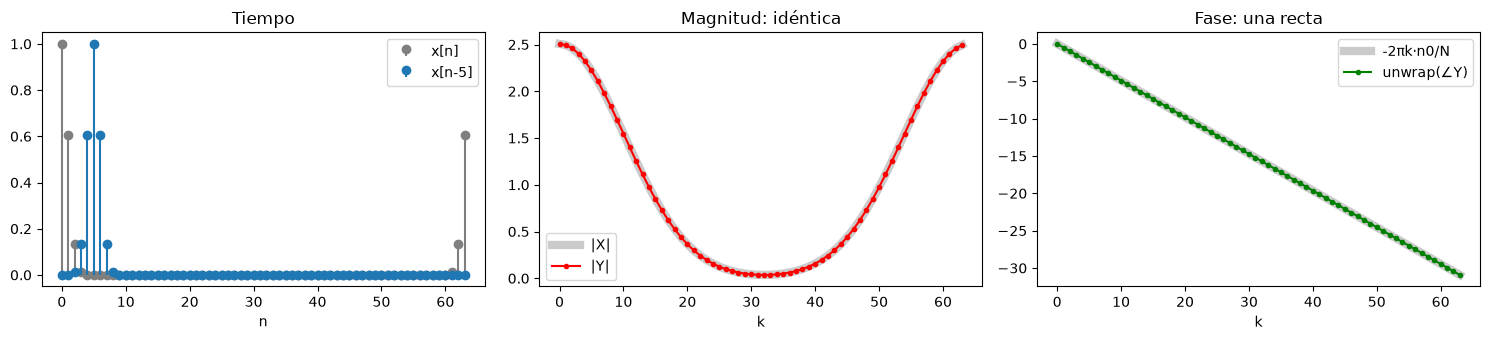

Y/X == e^(-j2πk·n0/N): True


In [1]:
import numpy as np
import matplotlib.pyplot as plt

N, n0 = 64, 5
n = k = np.arange(N)
x = np.exp(-((n + N//2) % N - N//2)**2 / 2)   # pulso centrado en n=0 → fase cero
y = np.roll(x, n0)                            # y[n] = x[n - n0]
X, Y = np.fft.fft(x), np.fft.fft(y)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].stem(n, x, linefmt='C7-', markerfmt='C7o', basefmt=" ", label="x[n]")
ax[0].stem(n, y, basefmt=" ", label=f"x[n-{n0}]")
ax[0].set_title("Tiempo"); ax[0].set_xlabel("n"); ax[0].legend()
ax[1].plot(k, np.abs(X), 'C7', lw=6, alpha=.4, label="|X|")
ax[1].plot(k, np.abs(Y), 'r.-', label="|Y|")
ax[1].set_title("Magnitud: idéntica"); ax[1].set_xlabel("k"); ax[1].legend()
ax[2].plot(k, -2*np.pi*k*n0/N, 'C7', lw=6, alpha=.4, label="-2πk·n0/N")
ax[2].plot(k, np.unwrap(np.angle(Y)), 'g.-', label="unwrap(∠Y)")
ax[2].set_title("Fase: una recta"); ax[2].set_xlabel("k"); ax[2].legend()
plt.tight_layout()
plt.show()

print("Y/X == e^(-j2πk·n0/N):", np.allclose(Y / X, np.exp(-2j*np.pi*k*n0/N)))